# Systemy AI – Laboratorium 5
## Zadanie: który klasyfikator najlepiej rozpoznaje cukrzycę?

Zbiór **Pima Indians Diabetes**: 768 kobiet z plemienia Pima (Arizona, USA). Zadanie: na podstawie wyników badań przewidzieć, czy u pacjentki zdiagnozowano cukrzycę w ciągu 5 lat (`outcome` = 1).

Wykonaj całą procedurę z notatnika `SystemyAI_Lab5_Titanic_CV.ipynb`: porównaj klasyfikatory walidacją krzyżową, dostrój hiperparametry, wybierz najlepszy model i **dopiero na końcu, raz**, oceń go na zbiorze testowym. Cały kod piszesz sam(a).

| Kolumna | Znaczenie |
|---|---|
| `pregnancies` | liczba ciąż |
| `glucose` | stężenie glukozy po 2 h w doustnym teście obciążenia glukozą [mg/dl] |
| `blood_pressure` | ciśnienie rozkurczowe [mm Hg] |
| `skin_thickness` | grubość fałdu skórnego na tricepsie [mm] |
| `insulin` | stężenie insuliny po 2 h [μU/ml] |
| `bmi` | wskaźnik masy ciała [kg/m²] |
| `pedigree` | wskaźnik obciążenia rodzinnego cukrzycą |
| `age` | wiek [lata] |
| `outcome` | **etykieta**: 1 = cukrzyca, 0 = brak |

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

---
## 1. Wczytanie danych
Plik nie ma wiersza nagłówka, więc nazwy kolumn trzeba podać samemu:

```python
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)
```
Zaimportuj potrzebne biblioteki, wczytaj dane do `df` i obejrzyj je (`shape`, `head()`, `describe()`).

In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, validation_curve, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
kolumny = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
           "insulin", "bmi", "pedigree", "age", "outcome"]
df = pd.read_csv(URL, names=kolumny)

print(df.shape)
display(df.head())
df.describe().round(1)

(768, 9)


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,pedigree,age,outcome
count,768.0,768.0,768.0,768.0,768.0,768.0,768.0,768.0,768.0
mean,3.8,120.9,69.1,20.5,79.8,32.0,0.5,33.2,0.3
std,3.4,32.0,19.4,16.0,115.2,7.9,0.3,11.8,0.5
min,0.0,0.0,0.0,0.0,0.0,0.0,0.1,21.0,0.0
25%,1.0,99.0,62.0,0.0,0.0,27.3,0.2,24.0,0.0
50%,3.0,117.0,72.0,23.0,30.5,32.0,0.4,29.0,0.0
75%,6.0,140.2,80.0,32.0,127.2,36.6,0.6,41.0,1.0
max,17.0,199.0,122.0,99.0,846.0,67.1,2.4,81.0,1.0


In [77]:
# TEST
assert df.shape == (768, 9) and list(df.columns)[-1] == "outcome"
print("1 OK")

1 OK


---
## 2. EDA i ukryte braki
1. `class_share` – udział każdej klasy w `outcome`.
2. `df.isna().sum()` – czy są braki? Teraz policz `zeros` – liczbę **zer** w każdej kolumnie cech.
3. Narysuj `fig, axes = plt.subplots(1, 2, figsize=(12, 5))`: po lewej histogram `glucose`, po prawej histogram `insulin`, oba z kolorem według `outcome` (`sns.histplot(..., hue="outcome")`).

outcome
0    0.651
1    0.349
Name: proportion, dtype: float64
pregnancies       0
glucose           0
blood_pressure    0
skin_thickness    0
insulin           0
bmi               0
pedigree          0
age               0
outcome           0
dtype: int64
pregnancies       111
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
pedigree            0
age                 0
dtype: int64


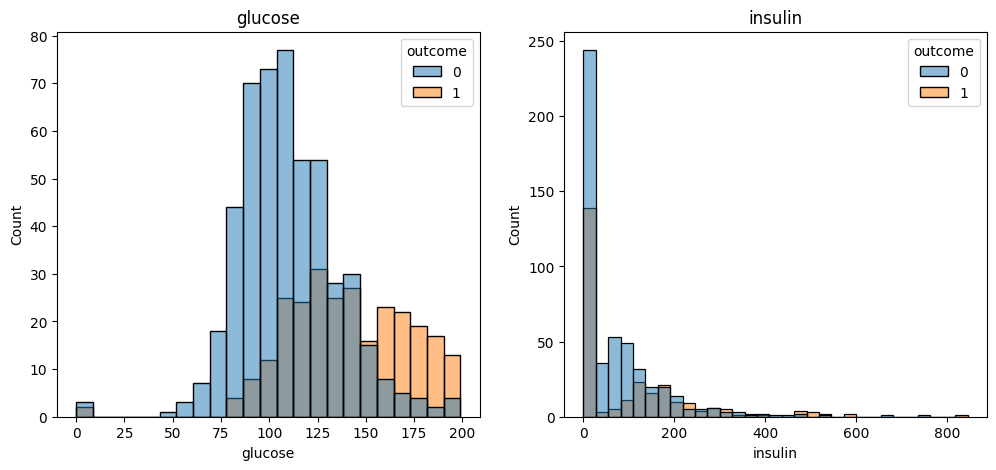

In [78]:
class_share = df["outcome"].value_counts(normalize=True)
print(class_share.round(3))

print(df.isna().sum())

zeros = (df.drop(columns="outcome") == 0).sum()
print(zeros)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="glucose", hue="outcome", ax=axes[0])
axes[0].set_title("glucose")
sns.histplot(data=df, x="insulin", hue="outcome", ax=axes[1])
axes[1].set_title("insulin")
plt.show()

In [79]:
# TEST
assert abs(class_share[0] - 0.651) < 1e-3
assert zeros["insulin"] == 374 and zeros["glucose"] == 5 and zeros["pregnancies"] == 111
print("2 OK")

2 OK


*Twoja odpowiedź:*
1. Jaką accuracy osiągnie baseline?
2. W których kolumnach zero jest **fizycznie niemożliwe** (żyjący człowiek nie może mieć takiej wartości), a w której jest zupełnie normalne?
3. Która cecha najwyraźniej różni chore i zdrowe pacjentki?

Odpowiedź:
1. Baseline zawsze przewiduje 0, więc jego accuracy to udział klasy 0, czyli ok. 0.651.
2. Zero jest fizycznie niemożliwe w glucose, blood_pressure, skin_thickness, insulin i bmi - to są braki pomiaru. W pregnancies zero jest normalne (brak ciąż).
3. glucose - u chorych pacjentek rozkład jest wyraźnie przesunięty w stronę wyższych wartości.

---
## 3. Zamiana ukrytych braków na `NaN`
W kolumnach `glucose`, `blood_pressure`, `skin_thickness`, `insulin`, `bmi` zamień zera na `np.nan` (`replace(0, np.nan)`). Wynik zapisz w `df_clean` (kopia `df`), a liczbę braków w każdej kolumnie w `missing`.

Model nie wie, że zero oznacza brak. Dla niego „insulina = 0” to po prostu bardzo niska insulina – a takich „pomiarów” jest prawie połowa.

In [80]:
df_clean = df.copy()
kol_braki = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]
df_clean[kol_braki] = df_clean[kol_braki].replace(0, np.nan)

missing = df_clean.isna().sum()
missing

,0
pregnancies,0
glucose,5
blood_pressure,35
skin_thickness,227
insulin,374
bmi,11
pedigree,0
age,0
outcome,0


In [81]:
# TEST
assert missing["insulin"] == 374 and missing["skin_thickness"] == 227 and missing["pregnancies"] == 0
assert (df["insulin"] == 0).sum() == 374, "Nie zmieniaj oryginalnego df - użyj copy()"
print("3 OK")

3 OK


*Twoja odpowiedź:* insuliny brakuje u prawie połowy pacjentek. Jakie masz możliwości? Co wybierasz i dlaczego?

Odpowiedź: można usunąć wiersze z brakami (strata prawie połowy danych), usunąć całą kolumnę insulin albo uzupełnić braki medianą (ewentualnie z flagą braku). Najrozsądniejsze jest uzupełnienie medianą w pipeline: nie traci się danych, a mediana jest liczona tylko na zbiorze treningowym. Mediana, a nie średnia, bo rozkład insuliny jest skośny.

---
## 4. Podział i przygotowanie
1. `X` – wszystkie cechy z `df_clean`, `y` – `outcome`. Podziel na `X_train, X_test, y_train, y_test` (`test_size=0.25`, `stratify=y`, `random_state=42`).
2. Napisz funkcję `model_z(klasyfikator)`, która zwraca pipeline: `SimpleImputer(strategy="median")` → `StandardScaler()` → klasyfikator. (Wszystkie cechy są liczbowe, więc `ColumnTransformer` nie jest potrzebny.)
3. Utwórz `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`.

In [82]:
X = df_clean.drop(columns="outcome")
y = df_clean["outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)


def model_z(klasyfikator):
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), klasyfikator)


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(X_train.shape, X_test.shape)

(576, 8) (192, 8)


In [83]:
# TEST
assert X_train.shape == (576, 8) and X_test.shape == (192, 8)
assert X_train["insulin"].isna().sum() > 0, "Podział robimy na df_clean (z NaN zamiast zer)"
assert len(model_z(None).steps) == 3
print("4 OK")

4 OK


---
## 5. Porównanie klasyfikatorów walidacją krzyżową
Dla pięciu modeli z domyślnymi hiperparametrami: `DummyClassifier(strategy="most_frequent")`, `LogisticRegression()`, `KNeighborsClassifier()`, `DecisionTreeClassifier(random_state=42)`, `RandomForestClassifier(random_state=42)` policz `cross_val_score` na zbiorze treningowym i accuracy na całym zbiorze treningowym.

Zbierz wyniki w tabeli `porownanie` (indeks: `"baseline"`, `"regresja logistyczna"`, `"kNN"`, `"drzewo decyzyjne"`, `"las losowy"`; kolumny: `"CV średnia"`, `"CV odch."`, `"train"`) i narysuj wykres słupkowy średnich z odchyleniami.

,CV średnia,CV odch.,train
model,,,
baseline,0.651,0.002,0.651
regresja logistyczna,0.778,0.025,0.790
kNN,0.736,0.021,0.835
drzewo decyzyjne,0.714,0.024,1.000
las losowy,0.748,0.014,1.000


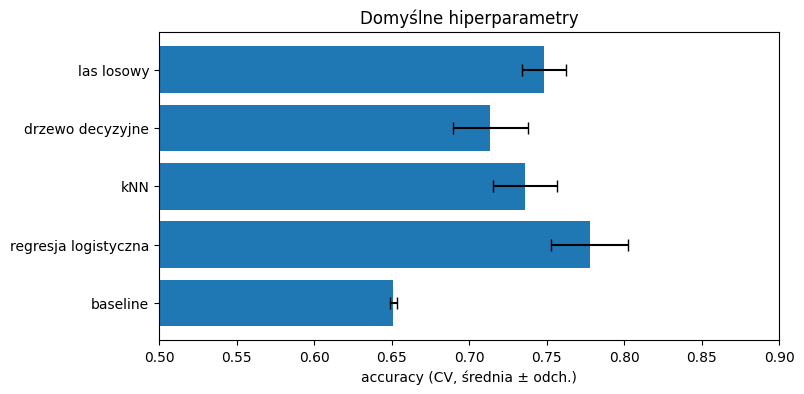

In [84]:
klasyfikatory = {
    "baseline": DummyClassifier(strategy="most_frequent"),
    "regresja logistyczna": LogisticRegression(),
    "kNN": KNeighborsClassifier(),
    "drzewo decyzyjne": DecisionTreeClassifier(random_state=42),
    "las losowy": RandomForestClassifier(random_state=42),
}

wiersze = []
for nazwa, klf in klasyfikatory.items():
    model = model_z(klf)
    s = cross_val_score(model, X_train, y_train, cv=cv)
    train_acc = model.fit(X_train, y_train).score(X_train, y_train)
    wiersze.append({"model": nazwa, "CV średnia": s.mean(), "CV odch.": s.std(), "train": train_acc})

porownanie = pd.DataFrame(wiersze).set_index("model")
display(porownanie.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(porownanie.index, porownanie["CV średnia"], xerr=porownanie["CV odch."], capsize=4)
ax.set_xlim(0.5, 0.9)
ax.set_xlabel("accuracy (CV, średnia ± odch.)")
ax.set_title("Domyślne hiperparametry")
plt.show()

In [85]:
# TEST
assert list(porownanie.index) == ["baseline", "regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"]
assert abs(porownanie.loc["baseline", "CV średnia"] - 0.651) < 1e-2
assert abs(porownanie.loc["regresja logistyczna", "CV średnia"] - 0.778) < 1e-2
assert porownanie.loc["drzewo decyzyjne", "train"] > 0.99
print("5 OK")

5 OK


---
## 6. Krzywa walidacji dla kNN
Policz `validation_curve` dla `kneighborsclassifier__n_neighbors` w `ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]`. Wyniki zapisz w `tren`, `walid`; narysuj średnie (trening i walidacja) w funkcji k.

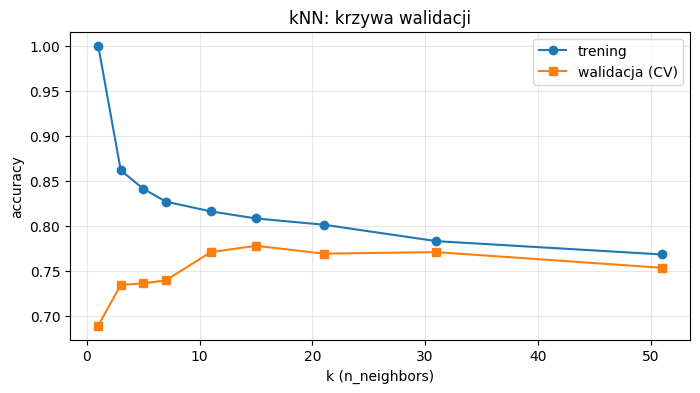

,1,3,5,7,11,15,21,31,51
trening,1.000,0.862,0.841,0.827,0.816,0.808,0.801,0.783,0.768
walidacja,0.689,0.734,0.736,0.740,0.771,0.778,0.769,0.771,0.753


In [86]:
ks = [1, 3, 5, 7, 11, 15, 21, 31, 51]
tren, walid = validation_curve(
    model_z(KNeighborsClassifier()), X_train, y_train,
    param_name="kneighborsclassifier__n_neighbors", param_range=ks, cv=cv)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ks, tren.mean(axis=1), "o-", label="trening")
ax.plot(ks, walid.mean(axis=1), "s-", label="walidacja (CV)")
ax.set_xlabel("k (n_neighbors)")
ax.set_ylabel("accuracy")
ax.set_title("kNN: krzywa walidacji")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

pd.DataFrame({"trening": tren.mean(axis=1), "walidacja": walid.mean(axis=1)}, index=ks).round(3).T

In [87]:
# TEST
assert tren.shape == (9, 5) and walid.shape == (9, 5)
assert tren.mean(axis=1)[0] == 1.0, "Dla k=1 wynik treningowy powinien wynosić 1.0"
print("6 OK")

6 OK


*Twoja odpowiedź:* dlaczego dla k = 1 wynik treningowy wynosi dokładnie 1.0? Gdzie jest przeuczenie, a gdzie niedouczenie?

Odpowiedź: dla k = 1 najbliższym sąsiadem punktu treningowego jest on sam, więc model zawsze zwraca jego własną etykietę - stąd 1.0. Przeuczenie widać przy małych k: dla k = 1 trening 1.000, a walidacja tylko 0.689. Najlepsza walidacja jest dla k = 15 (0.778). Przy dużych k model jest zbyt prosty (niedouczenie): dla k = 51 oba wyniki spadają (trening 0.768, walidacja 0.753)

---
## 7. Strojenie: `GridSearchCV`
Dla każdego z czterech klasyfikatorów uruchom `GridSearchCV(model_z(...), siatka, cv=cv)` na zbiorze treningowym. Siatki:
- regresja logistyczna: `C` ∈ {0.01, 0.1, 1, 10, 100},
- kNN: `n_neighbors` ∈ {1, 3, 5, 7, 11, 15, 21, 31},
- drzewo: `max_depth` ∈ {2, 3, 4, 5, 6, 8, None},
- las losowy: `max_depth` ∈ {3, 5, 8, None}, `n_estimators` ∈ {100, 300}.

Nauczone obiekty zapisz w słowniku `wyniki_gs` (klucze jak w punkcie 5, bez baseline'u) i wypisz najlepsze parametry oraz `best_score_` każdego modelu.

In [88]:
siatki = {
    "regresja logistyczna": (LogisticRegression(), {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}),
    "kNN": (KNeighborsClassifier(), {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 11, 15, 21, 31]}),
    "drzewo decyzyjne": (DecisionTreeClassifier(random_state=42),
                         {"decisiontreeclassifier__max_depth": [2, 3, 4, 5, 6, 8, None]}),
    "las losowy": (RandomForestClassifier(random_state=42),
                   {"randomforestclassifier__max_depth": [3, 5, 8, None],
                    "randomforestclassifier__n_estimators": [100, 300]}),
}

wyniki_gs = {}
for nazwa, (klf, siatka) in siatki.items():
    gs = GridSearchCV(model_z(klf), siatka, cv=cv)
    gs.fit(X_train, y_train)
    wyniki_gs[nazwa] = gs
    print(f"{nazwa:22s} {gs.best_params_}  CV = {gs.best_score_:.3f}")

regresja logistyczna   {'logisticregression__C': 1}  CV = 0.778
kNN                    {'kneighborsclassifier__n_neighbors': 15}  CV = 0.778
drzewo decyzyjne       {'decisiontreeclassifier__max_depth': 5}  CV = 0.750
las losowy             {'randomforestclassifier__max_depth': 3, 'randomforestclassifier__n_estimators': 300}  CV = 0.762


In [89]:
# TEST
assert set(wyniki_gs) == {"regresja logistyczna", "kNN", "drzewo decyzyjne", "las losowy"}
assert all(hasattr(gs, "best_estimator_") for gs in wyniki_gs.values())
assert all(gs.best_score_ > 0.7 for gs in wyniki_gs.values())
print("7 OK")

7 OK


---
## 8. Wybór modelu i ocena końcowa
1. `najlepszy` – nazwa modelu z najwyższym `best_score_`; `model_koncowy` – jego `best_estimator_`.
2. `acc_test` – accuracy `model_koncowy` na zbiorze testowym (**jedyny raz, kiedy używasz `X_test`**).
3. Macierz pomyłek (`ConfusionMatrixDisplay`) i `classification_report`.

wybrany model: regresja logistyczna {'logisticregression__C': 1}
CV:   0.778
test: 0.724


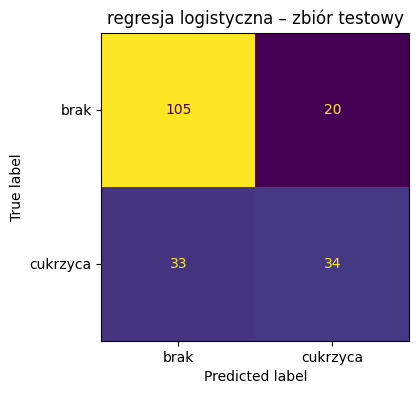

              precision    recall  f1-score   support

        brak      0.761     0.840     0.798       125
    cukrzyca      0.630     0.507     0.562        67

    accuracy                          0.724       192
   macro avg      0.695     0.674     0.680       192
weighted avg      0.715     0.724     0.716       192



In [90]:
najlepszy = max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
model_koncowy = wyniki_gs[najlepszy].best_estimator_

acc_test = model_koncowy.score(X_test, y_test)
print("wybrany model:", najlepszy, wyniki_gs[najlepszy].best_params_)
print(f"CV:   {wyniki_gs[najlepszy].best_score_:.3f}")
print(f"test: {acc_test:.3f}")

y_pred = model_koncowy.predict(X_test)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["brak", "cukrzyca"]).plot(ax=ax, colorbar=False)
ax.set_title(f"{najlepszy} – zbiór testowy")
plt.show()

print(classification_report(y_test, y_pred, target_names=["brak", "cukrzyca"], digits=3))

In [91]:
# TEST
assert najlepszy == max(wyniki_gs, key=lambda n: wyniki_gs[n].best_score_)
assert 0.65 < acc_test < 0.9
print("8 OK")

8 OK


*Twoja odpowiedź:*
1. Jak wynik testowy ma się do szacunku z walidacji krzyżowej? Czy różnica cię niepokoi? (Zbiór testowy ma 192 pacjentki - ile p.p. to jedna osoba?)
2. Jaki jest recall dla klasy „cukrzyca”? Co oznacza on dla pacjentek? Czy accuracy to dobra metryka do wyboru modelu w tym zastosowaniu?
3. Modele w czołówce różnią się w CV o 1-2 p.p., a odchylenia wynoszą ok. 2-3 p.p. Czy można jednoznacznie wskazać „najlepszy” algorytm?

Odpowiedź:
1. Wynik testowy wynosi 0.724, a szacunek z CV 0.778, czyli test jest niższy o ok. 5.4 p.p. Jedna pacjentka w teście to ok. 0.5 p.p. (1/192), więc to różnica ok. 10 pacjentek. Jest trochę większa niż odchylenie w CV, ale przy tak małym zbiorze testowym może wynikać z losowości podziału. Szacunek z CV jest też lekko zawyżony, bo wybrano najlepszą z wielu kombinacji.
2. Recall dla klasy „cukrzyca” wynosi 0.507, czyli model wykrywa tylko ok. połowę chorych (34 z 67), a 33 pacjentki zostają przeoczone (FN). W diagnostyce przeoczenie choroby jest groźniejsze niż fałszywy alarm, więc accuracy nie jest dobrą metryką do wyboru modelu - lepiej patrzeć na recall albo F1.
3. Nie. Regresja logistyczna i kNN mają po 0.778, las losowy 0.762, drzewo 0.750. Różnice są mniejsze lub porównywalne z odchyleniem w CV (2–3 p.p.), więc czołowe modele są w praktyce równie dobre.

---
## 9. Dla chętnych
1. Powtórz punkty 7–8 z `scoring="recall"` w `GridSearchCV`. Czy zmienił się wybrany model? Co stało się z precision?
2. Dodaj do imputera `add_indicator=True` (flagi braków). Czy sam fakt braku pomiaru insuliny niesie informację?
3. Sprawdź, jak wyglądałyby wyniki, gdyby zostawić zera zamiast `NaN` (punkt 3 pominięty). Czy różnica jest duża? Dlaczego może być mała?

In [92]:
wyniki_rec = {}
for nazwa, (klf, siatka) in siatki.items():
    gs = GridSearchCV(model_z(klf), siatka, cv=cv, scoring="recall")
    gs.fit(X_train, y_train)
    wyniki_rec[nazwa] = gs
    print(f"{nazwa:22s} {gs.best_params_}  recall CV = {gs.best_score_:.3f}")

najlepszy_rec = max(wyniki_rec, key=lambda n: wyniki_rec[n].best_score_)
model_rec = wyniki_rec[najlepszy_rec].best_estimator_
print("wybrany model:", najlepszy_rec)
print(classification_report(y_test, model_rec.predict(X_test), target_names=["brak", "cukrzyca"], digits=3))

regresja logistyczna   {'logisticregression__C': 1}  recall CV = 0.583
kNN                    {'kneighborsclassifier__n_neighbors': 3}  recall CV = 0.597
drzewo decyzyjne       {'decisiontreeclassifier__max_depth': 4}  recall CV = 0.652
las losowy             {'randomforestclassifier__max_depth': None, 'randomforestclassifier__n_estimators': 100}  recall CV = 0.582
wybrany model: drzewo decyzyjne
              precision    recall  f1-score   support

        brak      0.798     0.824     0.811       125
    cukrzyca      0.651     0.612     0.631        67

    accuracy                          0.750       192
   macro avg      0.725     0.718     0.721       192
weighted avg      0.747     0.750     0.748       192



Odpowiedź: przy scoring="recall" wybrane zostało drzewo decyzyjne (wcześniej regresja logistyczna). Recall dla cukrzycy wzrósł z 0.507 do 0.612, a precision nie spadła, tylko też wzrosła (z 0.630 do 0.651). Na tym zbiorze testowym drzewo wypadło lepiej w obu metrykach, ale test jest mały, więc może to być przypadek.

In [93]:
def model_flagi(klasyfikator):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), klasyfikator)

for nazwa, model in [("bez flag", model_z(LogisticRegression())), ("z flagami", model_flagi(LogisticRegression()))]:
    s = cross_val_score(model, X_train, y_train, cv=cv)
    print(f"{nazwa:10s} CV = {s.mean():.3f} ± {s.std():.3f}")

print(df_clean.groupby(df_clean["insulin"].isna())["outcome"].mean().round(3))

bez flag   CV = 0.778 ± 0.025
z flagami  CV = 0.767 ± 0.016
insulin
False    0.330
True     0.369
Name: outcome, dtype: float64


Odpowiedź: z flagami braków CV wynosi 0.767 ± 0.016, bez flag 0.778 ± 0.025. Flagi nie poprawiają wyniku, a różnica jest mniejsza niż odchylenie, więc sam fakt braku pomiaru insuliny niesie niewiele informacji. Potwierdza to odsetek chorych: wśród pacjentek z brakiem insuliny 0.369, a z pomiarem 0.330 - różnica jest niewielka.

In [94]:
X0_train = df.loc[X_train.index].drop(columns="outcome")

for nazwa, X_tr in [("NaN + mediana", X_train), ("zera", X0_train)]:
    s = cross_val_score(model_z(LogisticRegression()), X_tr, y_train, cv=cv)
    print(f"{nazwa:14s} CV = {s.mean():.3f} ± {s.std():.3f}")

NaN + mediana  CV = 0.778 ± 0.025
zera           CV = 0.778 ± 0.016


Odpowiedź: z zerami CV wynosi 0.778 ± 0.016, z NaN i medianą 0.778 ± 0.025 - średnia jest taka sama. Różnicy praktycznie nie ma. Może tak być, bo w glucose i bmi zer jest bardzo mało (5 i 11), a w insulin i skin_thickness, gdzie zer jest dużo, te cechy i tak mają mały wpływ na wynik. Poza tym zero działa jak osobny znacznik braku, którego model może się nauczyć.